# Three virtual asteroid nudges — **v10: continuous estimation + RL and OED**

**Research workflow in one notebook:** numerical tests → continuous 10-parameter estimator → sequential OED baseline → SAC training with optional imitation warm-start → paired RL/OED/random/hybrid evaluation → group-held-out symbolic policy distillation → closed-loop comparison → reproducible saved results.

The focus is **information gain only**. This v10 package deliberately excludes spacecraft/asteroid CBFs, MuJoCo contact, and any asteroid displacement or velocity penalty/keep-in constraint. Three virtual impulse events are planned sequentially. **All ten inertial estimates are refreshed after each sampled state**, including unfinished observation windows (not just once per nudge).

**Scope:** ideal impulsive, torque-free rigid-body surrogate; useful for experimental design, **not** a validated physical-contact controller. A learned SAC policy has no exact closed-form rule; the analytic OED equation below is the defensible mathematical selection rule, and a decision tree provides a *piecewise* approximation to the learned policy.

## 0 · Configuration — edit this one cell

**Run All works with `QUICK_MODE=True`** as a smoke-test demonstration. Change to `False` for the full research run (longer SAC training and more seeds). Both modes contain the *entire* workflow without terminal commands. Choose your existing `.venv` interpreter as the Jupyter kernel in VS Code.

The scientific comparisons use **training, distillation, and final evaluation seed ranges that do not overlap**.

In [15]:
from pathlib import Path
import sys, importlib.util, subprocess, os, time
import numpy as np

QUICK_MODE = False       # Change to False for the main research experiment
AUTO_INSTALL_MISSING = True  # Installs Python packages into THIS notebook's kernel only
RUN_NUMERICAL_TESTS = True
RUN_TRAINING = True       # Change to False to load an existing trained v10 SAC model
RUN_DISTILLATION = True
RUN_NOISE_SWEEP = True

TRAIN_STEPS = 1200 if QUICK_MODE else 40000
TEACHER_EPISODES = 20 if QUICK_MODE else 160
EVALUATION_EPISODES = 4 if QUICK_MODE else 30
DISTILL_EPISODES = 24 if QUICK_MODE else 150
CANDIDATES = 16 if QUICK_MODE else 64
TRAIN_SAMPLE_PERIOD_S = 1.0 if QUICK_MODE else 0.5
DIAGNOSTIC_SAMPLE_PERIOD_S = 0.25    # estimate is updated EVERY 0.25 seconds in the diagnostic trajectory
NOISE_STD = 1e-4
SEED = 19

cwd=Path.cwd().resolve()
ROOT=next((p for p in (cwd,cwd.parent,cwd.parent.parent) if (p/'model'/'asteroid.obj').exists() and (p/'src').exists()),None)
if ROOT is None:
    raise FileNotFoundError('Open notebook from the repository/notebooks directory; expected model/asteroid.obj and src/')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
OUT = ROOT/'results'/'three_nudge_v10'
OUT.mkdir(parents=True,exist_ok=True)
MODEL_PATH=OUT/'sac_oed_warmstart_v10'
print('Repository:', ROOT)
print('Python kernel:',sys.executable)
print('Mode:', 'QUICK research smoke test' if QUICK_MODE else 'FULL research evaluation')

Repository: /Users/aelkebir/active_inertial_id
Python kernel: /Library/Developer/CommandLineTools/usr/bin/python3
Mode: FULL research evaluation


## 1 · Check/install dependencies in Jupyter (no terminal)

If you see an installation message, restart the notebook kernel once so its modules load from the correct environment, then choose **Run All** again. Do not use Homebrew, system-wide `pip`, or `--break-system-packages`.

In [16]:
required={'numpy':'numpy','scipy':'scipy','matplotlib':'matplotlib','pandas':'pandas',
          'pytest':'pytest','gymnasium':'gymnasium','stable_baselines3':'stable-baselines3',
          'sklearn':'scikit-learn','nbformat':'nbformat','joblib':'joblib'}
missing=[pip_name for module,pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing and AUTO_INSTALL_MISSING:
    print('Installing into current kernel:',missing)
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
    print('Installation completed. Restart the kernel, then use Run All.')
elif missing:
    raise ImportError(f'Packages missing from notebook kernel: {missing}; set AUTO_INSTALL_MISSING=True')
else:print('All required modules appear available in the active Jupyter kernel.')

All required modules appear available in the active Jupyter kernel.


## 2 · Load the same physics and estimator used by both OED and RL

The estimator does *not* see the true mass/inertia. Surrogate ground truth is used only for scoring final errors. The policy action has **six components**: surface longitude, surface z, tangential push angle, tangential fraction, impulse, and force. The surface geometry comes from your asteroid mesh.

In [17]:
import pandas as pd, matplotlib.pyplot as plt
from src.inertial_dynamics import IDConfig,DesignConfig,REFERENCE_PI,com_inertia,action_to_nudge
from src.nudge_v10_workflow import (make_env,evaluate,summarize,paired_wins,save_evaluation,
    teacher_dataset,behavior_clone_actor,distill_tree,plot_error_distributions,
    plot_continuous_trace,per_parameter_summary,OBS_NAMES,ACTION_NAMES,run_episode)

icfg=IDConfig(sensor_sigma=NOISE_STD)
dcfg=DesignConfig(candidate_count=CANDIDATES,observe_s=30.0)
print('Noise sigma:',icfg.sensor_sigma,'| candidates:',dcfg.candidate_count,
      '| post-nudge observation:',dcfg.observe_s,'s')
print('Ten unknowns: m, mc_x, mc_y, mc_z, Ixx, Iyy, Izz, Ixy, Ixz, Iyz')
print('No asteroid drift penalty, translation bound or additional keep-in constraint.')

Noise sigma: 0.0001 | candidates: 64 | post-nudge observation: 30.0 s
Ten unknowns: m, mc_x, mc_y, mc_z, Ixx, Iyy, Izz, Ixy, Ixz, Iyz
No asteroid drift penalty, translation bound or additional keep-in constraint.


## 3 · Run numerical tests from inside this notebook

These test momentum conservation, inertia feasibility, analytic Jacobians, finite expected information gain, noiseless/noisy OED rollouts, and the **live estimator preview before a segment is committed**. Gymnasium/SB3 checker is run separately below. Tests are genuine assertions: if one fails, investigate before trusting any reported accuracy.

In [18]:
if RUN_NUMERICAL_TESTS:
    import pytest
    test_files=[str(ROOT/'tests'/'test_nudge_v10.py'),
                str(ROOT/'tests'/'test_nudge_v10_workflow.py')]
    exit_code=pytest.main(['-q',*test_files])
    if exit_code!=0:raise RuntimeError(f'Numerical tests failed; pytest code={exit_code}')
else: print('Numerical tests skipped by configuration.')

...............                                                          [100%]
=============================== warnings summary ===============================
tests/test_nudge_v10.py: 9 warnings
tests/test_nudge_v10_workflow.py: 2 warnings
  /Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
    denom=self.A@direction

tests/test_nudge_v10.py: 9 warnings
tests/test_nudge_v10_workflow.py: 2 warnings
  /Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
    denom=self.A@direction

tests/test_nudge_v10.py: 9 warnings
tests/test_nudge_v10_workflow.py: 2 warnings
  /Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
    denom=self.A@direction

tests/test_nudge_v10.py: 9 warnings
tests/test_nudge_v10_workflow.py: 2 warnings
  /Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: div

## 4 · Check Gymnasium interface & verify continuous parameter updates

One environment **step = one planned virtual nudge**. Within each step, the simulator generates many observation samples and updates the ten-parameter estimate at **each** sample. Setting `record_trace=True` stores every intermediate estimate; it does not expose the true parameters to the policy.

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

SB3 Gymnasium environment checker passed.
Continuous trace:  374 state-sample parameter updates
Three nudges, final errors: {'mass_error_kg': 0.12684134297768423, 'com_error_mm': 0.02191336512080619, 'inertia_error_kgm2': 1.141448535947126}
State after each of three nudges:
 nudge  impulse_Ns  force_N  pulse_s  numeric_rank  updates_so_far  mass_error_kg  com_error_mm  inertia_error_kgm2
     1     1.98381  2.14416  0.92522            10             124       57.94485      33.81734             9.52546
     2     1.58521  1.24965  1.26852            10             250        0.00928       0.07563             1.29505
     3     1.98975  2.54711  0.78118            10             374        0.12684       0.02191             1.14145


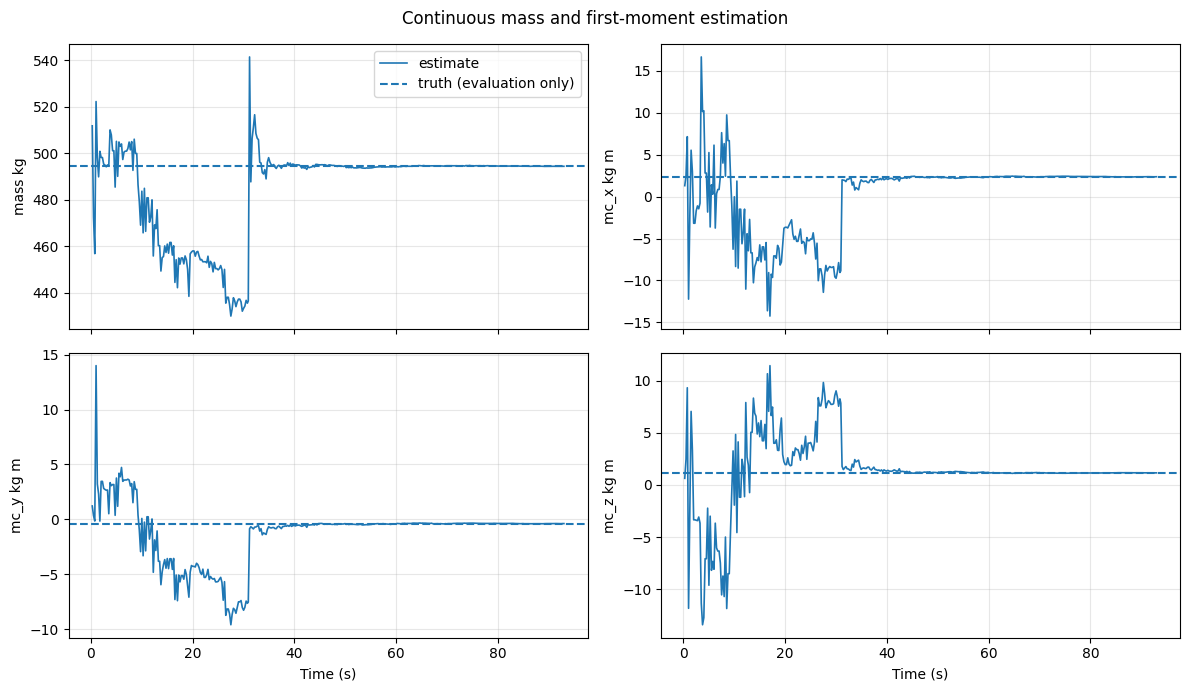

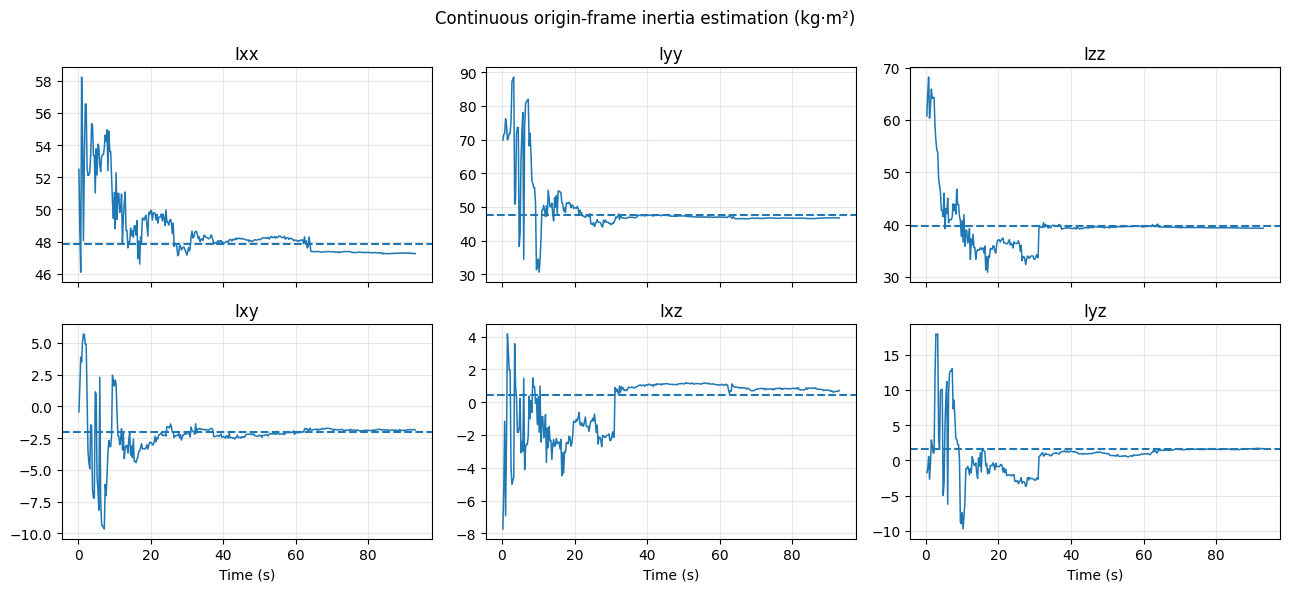

In [19]:
from stable_baselines3.common.env_checker import check_env
checker_env=make_env(ROOT,icfg,dcfg,sample_s=TRAIN_SAMPLE_PERIOD_S,debug=False)
try:
    check_env(checker_env,warn=True,skip_render_check=True)
finally:
    checker_env.close()
print('SB3 Gymnasium environment checker passed.')

trace_env=make_env(ROOT,icfg,dcfg,record_trace=True,
                   sample_s=DIAGNOSTIC_SAMPLE_PERIOD_S,debug=True)
try:
    trace_row,trace_ep=run_episode(trace_env,'oed',SEED,record_trace=True)
    print('Continuous trace: ',len(trace_ep['trace']), 'state-sample parameter updates')
    print('Three nudges, final errors:', {k:trace_row[k] for k in
          ('mass_error_kg','com_error_mm','inertia_error_kgm2')})
    trace_truth=trace_env.truth_pi.copy()   # EVALUATION ONLY, never a policy input
    assert trace_row['success'] and len(trace_ep['trace'])>3
    trace_env.save_trace_csv(OUT/'continuous_trace_v10.csv')
finally:trace_env.close()
per_nudge=pd.DataFrame([{
    'nudge':h['nudge'],'impulse_Ns':h['impulse_Ns'],'force_N':h['force_N'],
    'pulse_s':h['pulse_s'],'numeric_rank':h['numeric_rank'],
    'updates_so_far':h['estimator_updates'],
    **h['debug_truth_errors']} for h in trace_ep['nudges']])
print('State after each of three nudges:')
print(per_nudge.round(5).to_string(index=False))
per_nudge.to_csv(OUT/'per_nudge_diagnostics_v10.csv',index=False)
fig_mass,fig_inertia=plot_continuous_trace(trace_ep,truth_pi=trace_truth)
plt.show()

### Continuous confidence diagnostics (approximate)

Plot the changing *normalized* parameter standard deviations from the hybrid estimator after **each measurement**, including live previews. These are local information-based uncertainty proxies; they are **not calibrated confidence intervals**. A decreasing proxy must be checked against actual parameter errors on held-out episodes.

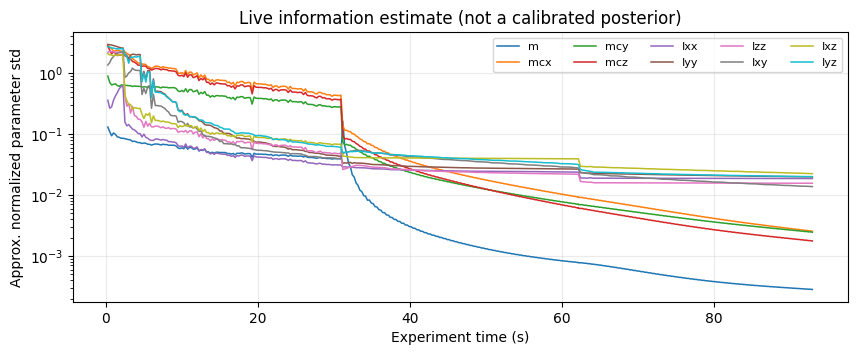

Per-nudge predicted reward components (kinematic vs angular information):
Nudge 1 {'kinematic_D': 33.5303074217275, 'kinematic_A': 0.7507502483704519, 'inertia_D': 53.712634524090404, 'inertia_A': 0.9994193825467931}
Nudge 2 {'kinematic_D': 24.686529376560237, 'kinematic_A': 0.9999884279073614, 'inertia_D': 6.8984485449463335, 'inertia_A': 0.7746518225696535}
Nudge 3 {'kinematic_D': 5.303002349638561, 'kinematic_A': 0.8588905485234464, 'inertia_D': 4.809025793018442, 'inertia_A': 0.5924307932903192}


In [20]:
trace_array=np.asarray(trace_ep['trace'],float)
assert trace_array.shape[1]==22
fig,ax=plt.subplots(figsize=(10,3.5))
for i,name in enumerate(('m','mcx','mcy','mcz','Ixx','Iyy','Izz','Ixy','Ixz','Iyz')):
    ax.plot(trace_array[:,0],np.maximum(trace_array[:,12+i],1e-14),
            label=name,linewidth=1.1)
ax.set_yscale('log');ax.set_ylabel('Approx. normalized parameter std')
ax.set_xlabel('Experiment time (s)');ax.set_title('Live information estimate (not a calibrated posterior)')
ax.grid(alpha=.25);ax.legend(ncol=5,fontsize=8);plt.show()
print('Per-nudge predicted reward components (kinematic vs angular information):')
for h in trace_ep['nudges']:
    print('Nudge',h['nudge'],h.get('reward_terms'))

## 5 · Random versus analytical OED (before RL)

The OED planner performs a **new optimization at every nudge boundary**, using the posterior information accumulated during previous nudges. No velocity, displacement or CBF term is in the reward. Use the **same seed list** for both methods and report absolute errors; a higher design reward by itself does not establish good identification.

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

seed=50000 random: mass=0.3958 kg  CoM=0.1388 mm  I=4.846 kg m²; success=True
seed=50000    oed: mass=0.1192 kg  CoM=0.01452 mm  I=2.227 kg m²; success=True
seed=50001 random: mass=0.1222 kg  CoM=0.4742 mm  I=10.38 kg m²; success=True
seed=50001    oed: mass=0.1956 kg  CoM=0.0434 mm  I=1.967 kg m²; success=True
seed=50002 random: mass=0.7824 kg  CoM=0.9553 mm  I=38.54 kg m²; success=True
seed=50002    oed: mass=0.2066 kg  CoM=0.1273 mm  I=2.042 kg m²; success=True
seed=50003 random: mass=0.02782 kg  CoM=2.799 mm  I=27.36 kg m²; success=True
seed=50003    oed: mass=0.1269 kg  CoM=0.2844 mm  I=4.17 kg m²; success=True
seed=50004 random: mass=0.1371 kg  CoM=0.1356 mm  I=9.994 kg m²; success=True
seed=50004    oed: mass=0.5846 kg  CoM=0.1262 mm  I=1.269 kg m²; success=True
seed=50005 random: mass=0.0223 kg  CoM=0.0136 mm  I=18.7 kg m²; success=True
seed=50005    oed: mass=0.1083 kg  CoM=0.03496 mm  I=0.711 kg m²; success=True
seed=50006 random: mass=0.2219 kg  CoM=0.06419 mm  I=4.788 kg m²

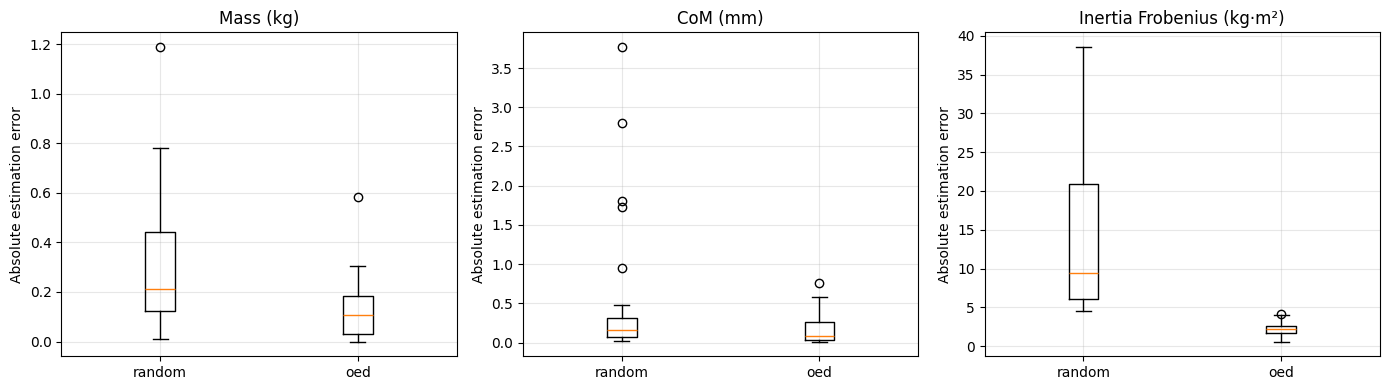

In [21]:
baseline_seeds=range(50000,50000+EVALUATION_EPISODES)
baseline_df,baseline_details=evaluate(ROOT,('random','oed'),baseline_seeds,
    icfg,dcfg,record_trace=False,sample_s=TRAIN_SAMPLE_PERIOD_S)
print(summarize(baseline_df).round(4).to_string(index=False))
save_evaluation(baseline_df,baseline_details,OUT/'baseline')
fig=plot_error_distributions(baseline_df);plt.show()

## 6 · Learn from OED, then train RL (SAC)

**Improvement over v9:** first collect OED teacher decisions on a **separate training seed range**, then train the SAC actor to imitate this strong teacher before reinforcement-learning fine-tuning. The imitation loss treats angular coordinates as periodic (the -1 and +1 ends represent the same direction). This is a *warm start*, not a guarantee that RL will beat OED.

The actor receives the 84-dimensional observation (current estimate, approximate information/covariance, pose/twist, nudge count). It never receives hidden true inertial parameters. Model files save under a new v10 name so your v9 SAC checkpoint remains unchanged.

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

32/160 teacher episodes
64/160 teacher episodes
96/160 teacher episodes
128/160 teacher episodes
160/160 teacher episodes
OED teacher decisions: 480
Using cpu device
Wrapping the env in a DummyVecEnv.
Behavior cloning: 480 decisions, loss 0.45588 -> 0.21474


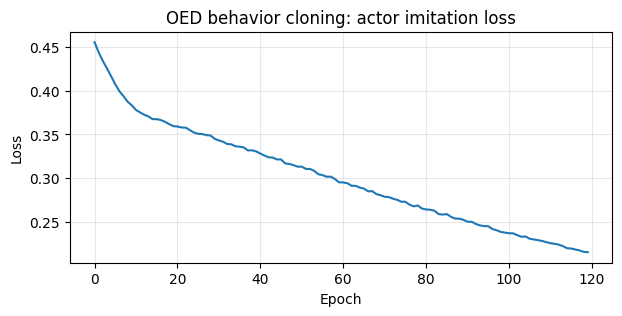

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 19.7     |
| time/              |          |
|    episodes        | 4        |
|    fps             | 20       |
|    time_elapsed    | 0        |
|    total_timesteps | 12       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 20       |
| time/              |          |
|    episodes        | 8        |
|    fps             | 20       |
|    time_elapsed    | 1        |
|    total_timesteps | 24       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 19.6     |
| time/              |          |
|    episodes        | 12       |
|    fps             | 20       |
|    time_elapsed    | 1        |
|    total_timesteps | 36       |
--------------

In [22]:
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from src.nudge_v10_workflow import make_env

if RUN_TRAINING:
    teacher_seeds=list(range(1000,1000+TEACHER_EPISODES))
    X_teacher,Y_teacher,G_teacher,U_teacher=teacher_dataset(ROOT,teacher_seeds,
        teacher='oed',icfg=icfg,dcfg=dcfg,sample_s=TRAIN_SAMPLE_PERIOD_S)
    print('OED teacher decisions:',len(X_teacher))
    train_env=Monitor(make_env(ROOT,icfg,dcfg,
        sample_s=TRAIN_SAMPLE_PERIOD_S,debug=False))
    try:
        sac=SAC('MlpPolicy',train_env,verbose=1,seed=SEED,device='cpu',
            learning_starts=150,buffer_size=50000,batch_size=128,
            gamma=.99,policy_kwargs=dict(net_arch=[128,128]))
        bc_history=behavior_clone_actor(sac,X_teacher,Y_teacher,
            epochs=60 if QUICK_MODE else 120)
        plt.figure(figsize=(7,3));plt.plot(bc_history);plt.title('OED behavior cloning: actor imitation loss')
        plt.xlabel('Epoch');plt.ylabel('Loss');plt.grid(alpha=.3);plt.show()
        sac.learn(total_timesteps=TRAIN_STEPS)
        sac.save(str(MODEL_PATH))
        print('Saved trained v10 SAC:',str(MODEL_PATH)+'.zip')
    finally:train_env.close()
else:
    sac=SAC.load(str(MODEL_PATH),device='cpu')
    print('Loaded previously saved v10 SAC:',MODEL_PATH)

## 7 · Matched policy comparison: random / OED / RL / hybrid

`hybrid` evaluates **one SAC candidate and the current OED candidate** at the same decision state, and executes whichever has higher predicted information utility. This can protect *model-predicted* utility compared with choosing the two candidates blindly, but it **does not guarantee lower true inertial-parameter error**.

Look first at **mass error (kg), CoM error (mm), inertia Frobenius error (kg·m²)**, p90 tails, and any failures—not only the mean reward.

seed=50000 random: mass=0.3958 kg  CoM=0.1388 mm  I=4.846 kg m²; success=True
seed=50000    oed: mass=0.1192 kg  CoM=0.01452 mm  I=2.227 kg m²; success=True
seed=50000     rl: mass=0.4513 kg  CoM=0.1325 mm  I=2.346 kg m²; success=True
seed=50000 hybrid: mass=0.1573 kg  CoM=0.0909 mm  I=2.038 kg m²; success=True
seed=50001 random: mass=0.1222 kg  CoM=0.4742 mm  I=10.38 kg m²; success=True
seed=50001    oed: mass=0.1956 kg  CoM=0.0434 mm  I=1.967 kg m²; success=True
seed=50001     rl: mass=0.2033 kg  CoM=0.2614 mm  I=3.206 kg m²; success=True
seed=50001 hybrid: mass=0.1956 kg  CoM=0.0434 mm  I=1.967 kg m²; success=True
seed=50002 random: mass=0.7824 kg  CoM=0.9553 mm  I=38.54 kg m²; success=True
seed=50002    oed: mass=0.2066 kg  CoM=0.1273 mm  I=2.042 kg m²; success=True
seed=50002     rl: mass=0.05785 kg  CoM=0.197 mm  I=2.344 kg m²; success=True
seed=50002 hybrid: mass=0.3385 kg  CoM=0.08907 mm  I=1.651 kg m²; success=True
seed=50003 random: mass=0.02782 kg  CoM=2.799 mm  I=27.36 kg m

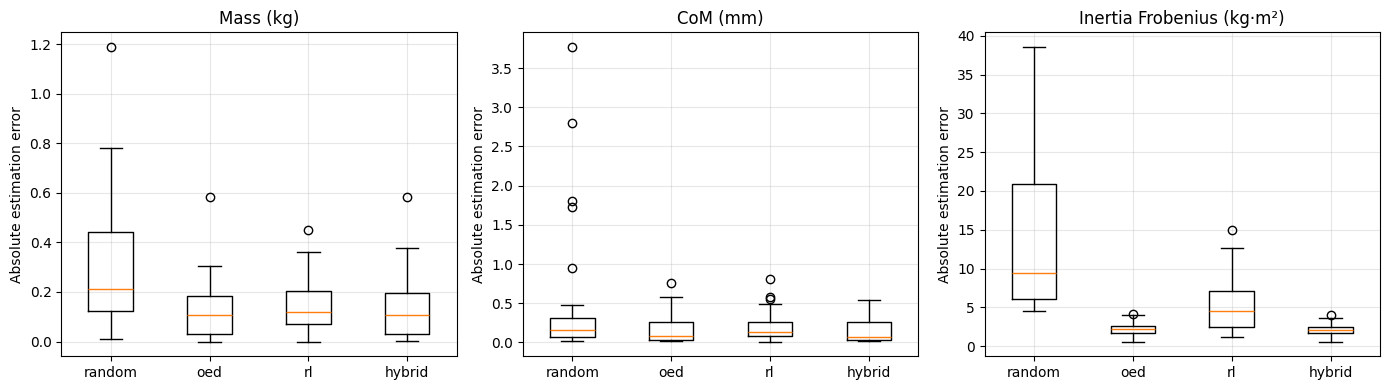

In [23]:
evaluation_seeds=range(50000,50000+EVALUATION_EPISODES)
comparison_df,comparison_details=evaluate(ROOT,
    policies=('random','oed','rl','hybrid'),seeds=evaluation_seeds,
    icfg=icfg,dcfg=dcfg,model=sac,sample_s=TRAIN_SAMPLE_PERIOD_S)
comparison_summary=summarize(comparison_df)
print(comparison_summary.round(5).to_string(index=False))
print('\nMedian absolute errors for each of the 10 parameters:')
print(per_parameter_summary(comparison_df).round(5).to_string())
print('Paired OED vs RL inertia:',paired_wins(comparison_df,'oed','rl'))
print('Paired hybrid vs OED inertia:',paired_wins(comparison_df,'hybrid','oed'))
print('Number of hybrid nudge selections where RL candidate won the design comparison:',
      comparison_df.loc[comparison_df.policy=='hybrid','hybrid_rl_selected'].sum())
save_evaluation(comparison_df,comparison_details,OUT/'matched_rl_oed_random_hybrid')
fig=plot_error_distributions(comparison_df);plt.show()

### Optional: objectively compare against your saved **v9 SAC** checkpoint

If the old v9 checkpoint exists, evaluate that frozen policy on the **exact same new seed list and v10 surrogate/estimator**. Otherwise, this cell simply skips. This is the direct test of whether v10 imitation warm-starting actually improved the trained policy, rather than assuming it did.

In [24]:
old_checkpoint=ROOT/'results'/'three_nudge_v9'/'sac_hybrid_v9.zip'
if old_checkpoint.exists():
    try:
        old_sac=SAC.load(str(old_checkpoint),device='cpu')
        old_df,_=evaluate(ROOT,('rl',),evaluation_seeds,
            icfg=icfg,dcfg=dcfg,model=old_sac,
            sample_s=TRAIN_SAMPLE_PERIOD_S,progress=False)
        old_df['policy']='v9_sac'
        new_df=comparison_df.loc[comparison_df.policy=='rl'].copy()
        new_df['policy']='v10_sac'
        both=pd.concat([old_df,new_df],ignore_index=True)
        print('Same seeds, same v10 estimator/environment:')
        print(summarize(both).round(5).to_string(index=False))
        both.to_csv(OUT/'v9_vs_v10_sac_matched.csv',index=False)
    except Exception as exc:
        print('v9 checkpoint could not be loaded into the v10 action/observation interface:',repr(exc))
else:
    print('No v9 SAC checkpoint found; comparison skipped. Looked for:',old_checkpoint)

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

Same seeds, same v10 estimator/environment:
 policy  episodes  successes  mass_error_kg_median  mass_error_kg_mean  mass_error_kg_p90  com_error_mm_median  com_error_mm_mean  com_error_mm_p90  inertia_error_kgm2_median  inertia_error_kgm2_mean  inertia_error_kgm2_p90  mean_reward
v10_sac        30         30               0.11844             0.14766            0.31310              0.13938            0.20357           0.49331                    4.55102                  5.65691                10.63321     20.80208
 v9_sac        30         30               0.09087             0.11330            0.20555              0.06348            0.12358           0.29559                    3.81358                  4.84629                 7.79582     21.22474


## 8 · Derive interpretable decision rules from OED and the trained SAC policy

To improve the earlier `MAE = 0.3679` result, train a decision tree on **many independent episodes**; tune tree depth on validation episodes and report **hold-out errors on entirely unseen episodes**. That prevents leakage from the same three-nudge sequence across splits. The tree exports explicit piecewise decision rules, not a closed-form proof of optimality.

We distill **both OED and SAC**. Distilling OED may produce a more reliable, physically motivated approximation if SAC is still weaker. Crucially, we *execute both trees* later; action MAE alone is not sufficient.

In [25]:
from pathlib import Path
rules_models={}
if RUN_DISTILLATION:
    distill_seeds=list(range(20000,20000+DISTILL_EPISODES))
    for teacher_name in ('oed','rl'):
        X,Y,groups,utilities=teacher_dataset(ROOT,distill_seeds,
            teacher=teacher_name,model=sac if teacher_name=='rl' else None,
            icfg=icfg,dcfg=dcfg,sample_s=TRAIN_SAMPLE_PERIOD_S)
        tree,report,rules=distill_tree(X,Y,groups,
            depth_choices=(3,4,6,8,10),
            min_samples_leaf=2 if QUICK_MODE else 4,
            output_dir=OUT/f'distilled_{teacher_name}')
        rules_models[teacher_name]=tree
        print('\nTEACHER:',teacher_name,'| selected depth:',report['chosen_tree_depth'],
              '| episode-heldout action MAE:',round(report['holdout_action_MAE'],4))
        print('Per-action MAE:',{k:round(v,3) for k,v in report['per_action_MAE'].items()})
        print('Beginning of symbolic tree rules:\n',rules[:2200])
else:
    import joblib
    for name in ('oed','rl'):
        rules_models[name]=joblib.load(OUT/f'distilled_{name}'/'interpretable_tree_v10.joblib')

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

30/150 teacher episodes
60/150 teacher episodes
90/150 teacher episodes
120/150 teacher episodes
150/150 teacher episodes

TEACHER: oed | selected depth: 3 | episode-heldout action MAE: 0.4788
Per-action MAE: {'longitude': 0.548, 'surface_z': 0.59, 'tangent_angle': 0.499, 'tangent_fraction': 0.562, 'impulse': 0.175, 'force': 0.498}
Beginning of symbolic tree rules:
 |--- normalized_pi_3 <= 0.0139
|   |--- cov_corr_4_8 <= 0.0129
|   |   |--- R_20 <= -0.0059
|   |   |   |--- value: [0.0092, -0.1209, -0.1430, 0.3026, 0.7284, -0.2022]
|   |   |--- R_20 >  -0.0059
|   |   |   |--- value: [0.1431, 0.1880, 0.1219, 0.2635, 0.7028, -0.1204]
|   |--- cov_corr_4_8 >  0.0129
|   |   |--- cov_corr_2_7 <= -0.1743
|   |   |   |--- value: [-0.2941, 0.3394, -0.1180, 0.3704, 0.7358, 0.6007]
|   |   |--- cov_corr_2_7 >  -0.1743
|   |   |   |--- value: [-0.3364, 0.3111, 0.3422, 0.2097, 0.6811, -0.2871]
|--- normalized_pi_3 >  0.0139
|   |--- cov_corr_5_7 <= 0.2995
|   |   |--- cov_corr_1_2 <= 0.4960
|   |

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

30/150 teacher episodes
60/150 teacher episodes
90/150 teacher episodes
120/150 teacher episodes
150/150 teacher episodes

TEACHER: rl | selected depth: 6 | episode-heldout action MAE: 0.3481
Per-action MAE: {'longitude': 0.446, 'surface_z': 0.517, 'tangent_angle': 0.42, 'tangent_fraction': 0.168, 'impulse': 0.135, 'force': 0.402}
Beginning of symbolic tree rules:
 |--- log_cov_8 <= -0.2117
|   |--- normalized_pi_2 <= 0.1005
|   |   |--- cov_corr_2_3 <= 0.9918
|   |   |   |--- normalized_pi_1 <= 0.6124
|   |   |   |   |--- normalized_pi_3 <= -0.0382
|   |   |   |   |   |--- normalized_pi_1 <= 0.1362
|   |   |   |   |   |   |--- value: [-0.7804, 0.3994, 0.8673, 0.8019, 0.9669, -0.1942]
|   |   |   |   |   |--- normalized_pi_1 >  0.1362
|   |   |   |   |   |   |--- value: [-0.0627, 0.6269, -0.3252, 0.4907, 0.9592, -0.4349]
|   |   |   |   |--- normalized_pi_3 >  -0.0382
|   |   |   |   |   |--- cov_corr_4_9 <= -0.3527
|   |   |   |   |   |   |--- value: [0.0719, 0.1482, 0.3360, 0.8037, 0

## 9 · Does the distilled tree actually work in closed loop?

A tree can imitate the teacher's actions closely but still lead to poor parameter estimates (or vice versa). Replay the tree as a policy: choose **three** actions from its rules, update the estimator continuously, and report final physical errors on the same held-out evaluation seeds.

In [12]:
tree_reports={}
for teacher_name in ('oed','rl'):
    policies=['random','oed','rl','tree_'+teacher_name]
    d,details=evaluate(ROOT,policies,evaluation_seeds,icfg,dcfg,
        model=sac,tree=rules_models[teacher_name],sample_s=TRAIN_SAMPLE_PERIOD_S)
    print('\nDistilled',teacher_name,'closed-loop errors:')
    print(summarize(d).round(5).to_string(index=False))
    save_evaluation(d,details,OUT/f'tree_closed_loop_{teacher_name}')
    tree_reports[teacher_name]=d

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

seed=50000 random: mass=0.3752 kg  CoM=0.1997 mm  I=6.53 kg m²; success=True
seed=50000    oed: mass=0.02197 kg  CoM=0.03377 mm  I=2.432 kg m²; success=True
seed=50000     rl: mass=0.1623 kg  CoM=0.1566 mm  I=18.39 kg m²; success=True
seed=50000 tree_oed: mass=0.1409 kg  CoM=0.1171 mm  I=8.994 kg m²; success=True
seed=50001 random: mass=0.04854 kg  CoM=0.7425 mm  I=11.11 kg m²; success=True


/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

seed=50001    oed: mass=0.1864 kg  CoM=0.1893 mm  I=2.635 kg m²; success=True
seed=50001     rl: mass=0.1625 kg  CoM=0.2062 mm  I=8.64 kg m²; success=True
seed=50001 tree_oed: mass=0.1654 kg  CoM=0.02529 mm  I=2.493 kg m²; success=True
seed=50002 random: mass=0.3085 kg  CoM=0.1948 mm  I=34.69 kg m²; success=True


/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

seed=50002    oed: mass=0.04862 kg  CoM=0.1564 mm  I=2.587 kg m²; success=True
seed=50002     rl: mass=0.3738 kg  CoM=0.1823 mm  I=6.969 kg m²; success=True
seed=50002 tree_oed: mass=0.3397 kg  CoM=0.3137 mm  I=1.651 kg m²; success=True
seed=50003 random: mass=0.09754 kg  CoM=0.1814 mm  I=19.12 kg m²; success=True


... (7 outputs left out)

seed=50002    oed: mass=0.04862 kg  CoM=0.1564 mm  I=2.587 kg m²; success=True
seed=50002     rl: mass=0.3738 kg  CoM=0.1823 mm  I=6.969 kg m²; success=True
seed=50002 tree_rl: mass=0.2712 kg  CoM=0.2823 mm  I=17.17 kg m²; success=True
seed=50003 random: mass=0.09754 kg  CoM=0.1814 mm  I=19.12 kg m²; success=True


/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

seed=50003    oed: mass=0.09499 kg  CoM=1.333 mm  I=2.947 kg m²; success=True
seed=50003     rl: mass=0.01538 kg  CoM=0.9028 mm  I=22.93 kg m²; success=True
seed=50003 tree_rl: mass=0.8835 kg  CoM=0.5234 mm  I=16.03 kg m²; success=True

Distilled rl closed-loop errors:
 policy  episodes  successes  mass_error_kg_median  mass_error_kg_mean  mass_error_kg_p90  com_error_mm_median  com_error_mm_mean  com_error_mm_p90  inertia_error_kgm2_median  inertia_error_kgm2_mean  inertia_error_kgm2_p90  mean_reward
    oed         4          4               0.07180             0.08800            0.15900              0.17286            0.42822           0.99016                    2.61079                  2.65005                 2.85331     21.22777
 random         4          4               0.20300             0.20745            0.35521              0.19728            0.32962           0.57970                   15.11930                 17.86490                30.02127     18.43970
     rl         4  

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

## 10 · Noise robustness: ideal data versus `1e-4` noise

Run the *same pretrained model* under noiseless and noisy measurements. These are **surrogate** outcomes; no claim about MuJoCo/robotic arm contact. An information-based reward can improve while true identification error worsens; always inspect both.

In [26]:
if RUN_NOISE_SWEEP:
    sweep_seeds=list(range(60000,60000+EVALUATION_EPISODES))
    all_sweep=[]
    for sensor_sigma in (0.,1e-4):
        cfg=IDConfig(sensor_sigma=sensor_sigma)
        df,details=evaluate(ROOT,('random','oed','rl','hybrid'),sweep_seeds,
            icfg=cfg,dcfg=dcfg,model=sac,sample_s=TRAIN_SAMPLE_PERIOD_S,progress=False)
        df['sensor_sigma']=sensor_sigma
        print('Noise sigma =',sensor_sigma)
        print(summarize(df).round(5).to_string(index=False))
        save_evaluation(df,details,OUT/f'noise_{sensor_sigma:g}')
        all_sweep.append(df)
    pd.concat(all_sweep,ignore_index=True).to_csv(OUT/'noise_sweep_all.csv',index=False)

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

Noise sigma = 0.0
policy  episodes  successes  mass_error_kg_median  mass_error_kg_mean  mass_error_kg_p90  com_error_mm_median  com_error_mm_mean  com_error_mm_p90  inertia_error_kgm2_median  inertia_error_kgm2_mean  inertia_error_kgm2_p90  mean_reward
hybrid        30         30                   0.0                 0.0                0.0                  0.0            0.00000           0.00000                    0.00705                  0.00749                 0.01103     22.29794
   oed        30         30                   0.0                 0.0                0.0                  0.0            0.00000           0.00000                    0.00629                  0.00740                 0.01246     22.21223
random        30         30                   0.0                 0.0                0.0                  0.0            0.00001           0.00001                    0.08013                  0.13066                 0.33359     20.33965
    rl        30         30           

/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: overflow encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull intersection invalid')
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: invalid value encountered in matmul
  if not np.all(self.A@pt+self.b<=1e-6): raise ValueError('Hull inter

Noise sigma = 0.0001
policy  episodes  successes  mass_error_kg_median  mass_error_kg_mean  mass_error_kg_p90  com_error_mm_median  com_error_mm_mean  com_error_mm_p90  inertia_error_kgm2_median  inertia_error_kgm2_mean  inertia_error_kgm2_p90  mean_reward
hybrid        30         30               0.09380             0.16052            0.34330              0.07040            0.15158           0.38056                    2.15521                  2.46393                 3.70178     21.74561
   oed        30         30               0.10190             0.18395            0.33074              0.12996            0.17288           0.38056                    2.19693                  2.50817                 4.67707     21.57264
random        30         30               0.32884             0.49490            0.91865              0.23886            0.69861           1.48385                   14.57840                 16.28596                32.23548     18.60249
    rl        30         30        

## 11 · Mathematical selection rule: what is (and is not) closed-form?

Given measured state $x(t)$, measured force impulse history, and current inertial estimate $\hat\pi_k$, continuously refresh the estimated information after each sample. With approximately independent measurement blocks $H_j$ and covariances $R_j$:

$$\Lambda_k=\Lambda_0+\sum_{j\le k}H_j^\mathsf T R_j^{-1}H_j,\qquad P_k\approx\Lambda_k^{-1}.$$

The predicted observation regressor $H(a;\hat\pi_k)$ for a candidate nudge $a=(p,\hat f,J,F)$ yields $\Delta\Lambda(a)$. The explicitly defined **one-step information-only OED rule** is

$$\boxed{a_k^*=\arg\max_{a\in\mathcal A}\;\log\frac{\det(\Lambda_k+\Delta\Lambda(a))}{\det(\Lambda_k)}+\eta\frac{\operatorname{tr}(P_k)-\operatorname{tr}[(\Lambda_k+\Delta\Lambda(a))^{-1}]}{\operatorname{tr}(P_k)}}$$

where the v10 hybrid estimator uses this **log-det / trace-reduction idea separately for kinematic and angular parameter blocks**. At $k+1$, repeat with *new measurements* and the updated parameter estimate. This is an **explicit mathematical optimization rule**, but the argmax is generally not an analytic closed-form solution for irregular asteroid mesh geometry and nonlinear motion. In practice it is evaluated over admissible Sobol candidates.

SAC instead learns $a_k=\pi_\theta(z_k)$, with $z_k$ containing the current estimates, approximate uncertainty, motion state, and nudge index. The distilled tree exports **piecewise rules** approximating $\pi_\theta$, which may not match the true optimum.

**Limitations:** the uncertainty is a *local, approximate* covariance with shared attitude-measurement errors; no formal posterior calibration, no contact constraints, no CBF or orbital/spacecraft reaction dynamics, no asteroid keep-in. The surrogate applies an ideal instantaneous impulse, while real finite-duration force profiles require validation later. Continuous updating means repeated updates at finite sample intervals; the three force decisions are separate by construction.

## 12 · Output files and research checklist

After Run All, everything is under `results/three_nudge_v10/`: the new SAC checkpoint, continuous traces, baseline tables, paired policy comparisons, symbolic tree rules, hold-out action errors, tree closed-loop evaluations, and noise robustness. The original v9 notebook and models remain untouched.

Before interpreting RL as better than OED, verify: (a) **independent evaluation seeds**, (b) ≥30–100 episodes and multiple SAC training seeds, (c) final errors of *each* inertial coefficient in addition to aggregate Frobenius error, (d) calibrated uncertainty and model mismatch tests, and (e) eventually MuJoCo/physical-contact validation in a **separate safety-specific project**. The notebook intentionally does not run or test a CBF.

In [14]:
print('Done. Outputs saved in:',OUT)
print('Trained SAC model:',str(MODEL_PATH)+'.zip')
for file in sorted(OUT.rglob('*')):
    if file.is_file() and file.suffix in ('.csv','.txt','.json','.zip','.joblib'):
        print(' -',file.relative_to(ROOT))

Done. Outputs saved in: /Users/aelkebir/active_inertial_id/results/three_nudge_v10
Trained SAC model: /Users/aelkebir/active_inertial_id/results/three_nudge_v10/sac_oed_warmstart_v10.zip
 - results/three_nudge_v10/baseline/episode_metrics.csv
 - results/three_nudge_v10/baseline/rollouts.json
 - results/three_nudge_v10/baseline/summary.csv
 - results/three_nudge_v10/continuous_trace_v10.csv
 - results/three_nudge_v10/distilled_oed/distillation_report_v10.json
 - results/three_nudge_v10/distilled_oed/interpretable_tree_v10.joblib
 - results/three_nudge_v10/distilled_oed/policy_rules_v10.txt
 - results/three_nudge_v10/distilled_rl/distillation_report_v10.json
 - results/three_nudge_v10/distilled_rl/interpretable_tree_v10.joblib
 - results/three_nudge_v10/distilled_rl/policy_rules_v10.txt
 - results/three_nudge_v10/matched_rl_oed_random_hybrid/episode_metrics.csv
 - results/three_nudge_v10/matched_rl_oed_random_hybrid/rollouts.json
 - results/three_nudge_v10/matched_rl_oed_random_hybrid/su